# MIB IOI: exact interactions and prediction across prompts

GPT-2 Small, official MIB IOI data, counterfactual attention-head patching.
This notebook uses the existing project CUDA environment. It does not change the
baseline notebook. Helper code is in `mib_ioi/`; official implementations are
imported from the local MIB checkout. Run cells incrementally; flags below control
expensive stages. No conclusions are populated before results exist.

**Execution profile: reduced 16-example integration smoke test.**

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from functools import partial
import hashlib
import importlib.metadata
import inspect
import itertools
import json
import math
import os
import uuid

ROOT = Path.cwd().resolve()
if not (ROOT / 'mib_ioi/runtime.py').is_file():
    raise RuntimeError('Start this notebook from the circuit-sketching repository root.')
os.environ['HF_HOME'] = str(ROOT / '.cache/huggingface')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from mib_ioi import runtime as rt, analysis as an

SEED = 42
DEVICE = 'cuda'
MIB_REPO = Path(os.environ.get('MIB_REPO', ROOT / 'external/MIB-circuit-track'))
N_TRAIN, N_VALIDATION, N_PUBLIC_TEST = 16, 16, 16
N_COMPONENTS = 12                        # supported range: 12--16
BATCH_SIZE = 8                          # reduce to 4 or 2 explicitly on OOM
EAP_BATCH_SIZE, N_EAP_EXAMPLES = 4, 16
MIB_EVAL_BATCH_SIZE, N_MIB_EVAL_EXAMPLES = 4, 8
TRAIN_MASKS_PER_DENSITY, EVAL_MASKS_PER_DENSITY = 64, 16
BOOTSTRAP_REPEATS = 100
SAMPLE_SIZES, SAMPLE_REPEATS = [4, 8, 16], 2
MEANINGFUL_INTERACTION_RATIO = 0.05      # prespecified exploratory effect-size criterion
RANK_STABILITY_THRESHOLD = 0.90         # descriptive, conditional on selected heads

RUN_EAP_SELECTION = True
RUN_SINGLETONS = True
RUN_PAIRS = True
RUN_RANDOM_MASKS = True
RUN_FITS = True
RUN_SAMPLE_EFFICIENCY = True
RUN_MIB_EVALUATION = True                # small official node-level validation run
RUN_PUBLIC_TEST = False                 # opt in only after fixing experimental choices
COMPONENTS_FILE = None                  # prior selected_components.csv if skipping EAP
RESUME_DIR = 'H:\\GenAI Research\\sketch_prune\\results\\mib_ioi_20261014T222524Z_f369a20c'                       # prior run directory; cache signature must match

rt.seed_everything(SEED)
assert 12 <= N_COMPONENTS <= 16
assert min(BATCH_SIZE, EAP_BATCH_SIZE, N_TRAIN, N_VALIDATION) > 0
assert BOOTSTRAP_REPEATS >= 100
RUN_DIR = (Path(RESUME_DIR).resolve() if RESUME_DIR else
           ROOT / 'results' / ('mib_ioi_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
                              + '_' + uuid.uuid4().hex[:8]))
RUN_DIR.mkdir(parents=True, exist_ok=True)
ledger = rt.Ledger(DEVICE, RUN_DIR)
print('Output:', RUN_DIR)
print('Flags:', {k: v for k, v in globals().copy().items() if k.startswith('RUN_') and isinstance(v, bool)})

Seed: 42; TF32 disabled; model.eval() used.
Output: H:\GenAI Research\sketch_prune\results\mib_ioi_20261014T222524Z_f369a20c
Flags: {'RUN_EAP_SELECTION': True, 'RUN_SINGLETONS': True, 'RUN_PAIRS': True, 'RUN_RANDOM_MASKS': True, 'RUN_FITS': True, 'RUN_SAMPLE_EFFICIENCY': True, 'RUN_MIB_EVALUATION': True, 'RUN_PUBLIC_TEST': False}


## 1. Verified repository conventions

Inspected checkout: MIB `b759df34433c9e31043ba9e02908ce0bf20e894f`, EAP submodule
`7af394a5662de8b23ad6154716a0cd3993d447a3`. Current paths, commits, signatures,
and source hashes are recorded below; a different installation is never substituted.

- `MIB_circuit_track/utils.py`: model key `gpt2` maps to TransformerLens
  `gpt2-small`; task key `ioi` maps to `mib-bench/ioi`.
- `HFEAPDataset` calls Hugging Face `load_dataset(..., split=...)` for
  `train`, `validation`, or public `test`, then applies its official name-token-length filter.
- Each loaded item is `(clean_prompt, corrupted_prompt, [correct_id, incorrect_id])`.
  IOI uses `s2_io_flip_counterfactual`; labels are the leading-space indirect-object
  and subject name tokens. The downloaded rows also expose `template` and `metadata`.
- `get_metric('logit_diff', 'ioi', ...)` subtracts subject from indirect-object
  logits at the final **unpadded** token. `get_metric('acc', ...)` supplies vocabulary
  top-1 accuracy. Corrupted scores below retain the clean labels, as MIB does.
- `eap.utils.tokenize_plus` prepends BOS and right-pads. Graph attention nodes
  expose `hook_result` with dimensions `[batch, position, head, d_model]`.
- `run_attribution.py` exposes a TransformerLens model and calls `attribute_node`
  for node attribution. The API requires uppercase **`EAP`**, despite the README's
  lowercase spelling. Gradients are enabled only during attribution.
- MIB exact node patching removes the node's outgoing edges and uses activations
  from the matched corrupted input. The direct output-replacement adapter below
  is checked against `eap.evaluate.evaluate_graph` on an exact single-head intervention.
- `evaluate_area_under_curve` supplies official node-level validation scores;
  `area_under` / `area_from_1` are reported under their actual API field names.
  Public test is available locally; private leaderboard evaluation requires submission.
- This checkout's `Graph.to_json` tries to index a node score for the sink
  `logits` node and raises `IndexError`. Use official `Graph.to_pt` / `from_pt`
  instead and verify the score round-trip; the upstream checkout is unchanged.

In [2]:
repo, provenance = rt.configure_repository(ROOT, MIB_REPO)
from MIB_circuit_track.dataset import HFEAPDataset
from MIB_circuit_track.metrics import get_metric
from MIB_circuit_track.utils import MODEL_NAME_TO_FULLNAME, TASKS_TO_HF_NAMES
from MIB_circuit_track.evaluation import evaluate_area_under_curve
from eap.graph import Graph
from eap.attribute_node import attribute_node
from eap.utils import tokenize_plus

print('MIB:', provenance['mib_commit'], '| EAP:', provenance['eap_commit'])
print('Model:', MODEL_NAME_TO_FULLNAME['gpt2'], '| Dataset:', 'mib-bench/' + TASKS_TO_HF_NAMES['ioi'])
for function in (HFEAPDataset, get_metric, tokenize_plus, attribute_node, evaluate_area_under_curve):
    print(function.__name__, inspect.signature(function))
rt.write_json(RUN_DIR / 'repository_provenance.json', provenance)
with ledger.stage('model_loading', 'one GPT-2 Small model; no task forwards expected'):
    model = rt.load_model(DEVICE)
print(torch.cuda.get_device_name(0), '| dtype:', model.cfg.dtype)

MIB: b759df34433c9e31043ba9e02908ce0bf20e894f | EAP: 7af394a5662de8b23ad6154716a0cd3993d447a3
Model: gpt2-small | Dataset: mib-bench/ioi
HFEAPDataset (url: str, tokenizer: transformers.tokenization_utils.PreTrainedTokenizer, split: str = 'train', task: str = 'ioi', num_examples: Optional[int] = None, control: Optional[bool] = False, counterfactual_type: Optional[str] = None, example_domain: Optional[str] = None, model_name: Optional[str] = None, hf_token: Optional[str] = None)
get_metric (metric_name: str, task: str, tokenizer: Optional[transformers.tokenization_utils.PreTrainedTokenizer] = None, model: Optional[transformer_lens.HookedTransformer.HookedTransformer] = None, model_name: Optional[str] = None)
tokenize_plus (model: transformer_lens.HookedTransformer.HookedTransformer, inputs: List[str], max_length: Optional[int] = None)
attribute_node (model: transformer_lens.HookedTransformer.HookedTransformer, graph: eap.graph.Graph, dataloader: torch.utils.data.dataloader.DataLoader, me

Loaded pretrained model gpt2-small into HookedTransformer
model_loading: 0 actual forward batches, 1.93s wall


NVIDIA GeForce RTX 3060 | dtype: torch.float32


## 2. Official split loading and reproducible subsets

Subsample **within** each official filtered split using seeded permutations; never
create new train/validation boundaries. Check exact clean-prompt overlap across
the full filtered splits, record source indices/fingerprints, and retain actual
metadata. Public test is loaded/evaluated only if its flag is enabled.

In [3]:
sizes = {'train': N_TRAIN, 'validation': N_VALIDATION}
if RUN_PUBLIC_TEST:
    sizes['test'] = N_PUBLIC_TEST
with ledger.stage('data_loading', f'official splits: {sizes}; no model forwards'):
    datasets, examples, dataset_info = rt.load_splits(model, sizes, SEED)
examples.to_csv(RUN_DIR / 'ioi_examples.csv', index=False)
rt.write_json(RUN_DIR / 'dataset_manifest.json', dataset_info)
print('Full filtered split overlaps:', dataset_info['full_filtered_split_clean_prompt_overlap'])
display(examples.groupby('split', sort=False).head(2)[[
    'split', 'clean_prompt', 'corrupted_prompt', 'correct_answer', 'incorrect_answer', 'metadata']])
print('Available raw fields:', datasets['train'].dataset.column_names)
display(pd.DataFrame([datasets['train'].dataset[i] for i in range(2)])[['template', 'metadata']])

data_loading: official splits: {'train': 16, 'validation': 16}; no model forwards


data_loading: 0 actual forward batches, 5.07s wall


Full filtered split overlaps: {'train__validation': 0}


,split,clean_prompt,corrupted_prompt,correct_answer,incorrect_answer,metadata
0,train,When Christian and Maria got a pitcher at the ...,When Christian and Maria got a pitcher at the ...,Maria,Christian,"{""indirect_object"": ""Maria"", ""object"": ""pitche..."
1,train,Just as Kevin and Louis were leaving the marin...,Just as Kevin and Louis were leaving the marin...,Louis,Kevin,"{""indirect_object"": ""Louis"", ""object"": ""pictur..."
16,validation,"Later, Joseph and June met at the factory. Jos...","Later, Joseph and June met at the factory. Jun...",June,Joseph,"{""indirect_object"": ""June"", ""object"": ""wheelba..."
17,validation,"Then, Mark and Joseph were thinking about goin...","Then, Mark and Joseph were thinking about goin...",Joseph,Mark,"{""indirect_object"": ""Joseph"", ""object"": ""cushi..."


Available raw fields: ['template', 'metadata', 'prompt', 'choices', 'answerKey', 'abc_counterfactual', 'random_names_counterfactual', 's1_io_flip_counterfactual', 's2_io_flip_counterfactual', 'random_names_s1_ioi_flip_counterfactual', 'random_names_s2_ioi_flip_counterfactual', 's1_ioi_flip_s2_ioi_flip_counterfactual', 'random_names_s1_ioi_flip_s2_ioi_flip_counterfactual']


,template,metadata
0,When {name_A} and {name_B} got a {object} at t...,"{'indirect_object': 'Maria', 'object': 'pitche..."
1,Just as {name_A} and {name_B} were leaving the...,"{'indirect_object': 'Louis', 'object': 'pictur..."


## 3. Reproduce the official raw IOI score

`evaluate_ioi_batch` is a thin wrapper around the official tokenizer/metrics.
Raw logit difference, intervention effect (patched minus clean), and official
CPR/CMD-style circuit evaluations are separate outputs. A positive clean
logit difference means the correct name beats the distractor, not necessarily
every vocabulary token. Top-1 accuracy is also reported.

In [4]:
# One graph-defined head is used only for the correctness probe; selection comes next.
probe_node = next(n for n in Graph.from_model(model).nodes.values() if hasattr(n, 'head'))
probe_scorer = rt.IOIScorer(model, datasets, [(probe_node.layer, probe_node.head)],
                           BATCH_SIZE, ledger, RUN_DIR / 'probe_cache')
baseline_rows = []
with ledger.stage('raw_ioi_scores', f'{2*sum(math.ceil(len(d)/BATCH_SIZE) for d in datasets.values())} '
                  'forward batches for clean/corrupted scores'), ledger.instrument(model):
    for split in datasets:
        for corrupted in (False, True):
            score, accuracy = probe_scorer.score(split, corrupted=corrupted, use_cache=False)
            baseline_rows.append({'prompt_split': split, 'input': 'corrupted' if corrupted else 'clean',
                                  'mean_logit_diff': score.mean(), 'top1_accuracy': accuracy.mean(),
                                  'correct_over_distractor_rate': (score > 0).mean(),
                                  'n_examples': len(score), 'batch_size': BATCH_SIZE})
baseline_results = pd.DataFrame(baseline_rows)
baseline_results.to_csv(RUN_DIR / 'raw_ioi_scores.csv', index=False)
display(baseline_results)
if (baseline_results.query("input == 'clean'").mean_logit_diff <= 0).any():
    raise RuntimeError('Clean mean IOI logit difference is nonpositive; investigate model/data before proceeding.')
display(pd.DataFrame(ledger.stages).tail(1))

raw_ioi_scores: 8 forward batches for clean/corrupted scores


raw_ioi_scores: 8 actual forward batches, 1.13s wall


,prompt_split,input,mean_logit_diff,top1_accuracy,correct_over_distractor_rate,n_examples,batch_size
0,train,clean,2.899391,0.8125,0.9375,16,8
1,train,corrupted,-2.145477,0.0000,0.1250,16,8
2,validation,clean,2.610751,0.6875,0.9375,16,8
3,validation,corrupted,-2.969111,0.0000,0.0625,16,8


,stage,success,forward_passes_batches,successful_forward_passes,examples_processed,forward_seconds,wall_seconds,backward_calls,cache_hits,new_unique_masks,unique_masks_cumulative,component_count,peak_cuda_allocated_mib,peak_cuda_reserved_mib
2,raw_ioi_scores,True,8,8,64,0.969116,1.129269,0,0,1,1,1,1106.602051,1168.0


## 4. One exact causal intervention and recovery checks

Fresh forwards verify hook removal, deterministic repeat, batched versus single-example
evaluation, the raw MIB baseline, and equivalence to official graph patching.
The probe head is a correctness fixture, not the research component set.

In [5]:
with ledger.stage('exact_intervention_checks', '4 prompts, one head, approximately 25 forward batches'), ledger.instrument(model):
    intervention_checks = rt.verify_intervention(probe_scorer, count=4)
rt.write_json(RUN_DIR / 'intervention_checks.json', intervention_checks)
display(pd.DataFrame([intervention_checks]))
probe_scorer.donors.clear()
del probe_scorer

exact_intervention_checks: 4 prompts, one head, approximately 25 forward batches


exact_intervention_checks: 18 actual forward batches, 1.41s wall


,n_examples,head,mean_effect,hook_removal_max_error,determinism_max_error,batching_max_error,official_graph_max_error,tolerance
0,4,"[0, 0]",-0.00351,0.0,0.0,0.000009,0.000017,0.0003


## 5. Select heads using the official EAP baseline

Run node EAP on a small **training-only** subset and select the top 12--16 attention
heads by absolute official attribution. The graph includes MLP/input nodes, but the
controlled interaction experiment selects attention heads only. The full graph is
saved unchanged for the official baseline evaluation later. Selection is fixed
before examining validation/test effects. A saved component CSV can be supplied
to skip EAP when running only exact experiments.

In [6]:
eap_graph, ranking = None, None
if RUN_EAP_SELECTION:
    if N_EAP_EXAMPLES > len(datasets['train']):
        raise ValueError('N_EAP_EXAMPLES exceeds the selected training subset.')
    eap_data = rt.subset(datasets['train'], range(N_EAP_EXAMPLES))
    with ledger.stage('official_eap_selection',
                      f'{math.ceil(N_EAP_EXAMPLES/EAP_BATCH_SIZE)} attribution batches; '
                      f'{3*math.ceil(N_EAP_EXAMPLES/EAP_BATCH_SIZE)} forwards plus '
                      f'{math.ceil(N_EAP_EXAMPLES/EAP_BATCH_SIZE)} backwards'), ledger.instrument(model):
        eap_graph, ranking = rt.official_eap(model, eap_data, EAP_BATCH_SIZE, ledger)
    ranking.to_csv(RUN_DIR / 'official_eap_head_ranking.csv', index=False)
    selected = ranking.head(N_COMPONENTS).copy()
    selected['selection_source'] = 'official node EAP on train'
    eap_path = RUN_DIR / 'official_eap_node_importances.pt'
    eap_graph.to_pt(str(eap_path))
    reloaded = Graph.from_pt(str(eap_path))
    torch.testing.assert_close(reloaded.nodes_scores, eap_graph.nodes_scores, equal_nan=True)
    eap_config = {'api': 'eap.attribute_node.attribute_node', 'method': 'EAP', 'intervention': 'patching',
                  'level': 'node', 'aggregation': 'sum', 'metric': 'logit_diff', 'mean': True, 'loss': True,
                  'model': 'gpt2', 'task': 'ioi', 'split': 'train', 'n_examples': N_EAP_EXAMPLES,
                  'batch_size': EAP_BATCH_SIZE, 'seed': SEED,
                  'selected_filtered_indices': dataset_info['train']['selected_filtered_indices'][:N_EAP_EXAMPLES],
                  'artifact': str(eap_path), 'mib_commit': provenance['mib_commit'],
                  'eap_commit': provenance['eap_commit']}
    rt.write_json(RUN_DIR / 'official_eap_config.json', eap_config)
elif COMPONENTS_FILE:
    selected = pd.read_csv(COMPONENTS_FILE).head(N_COMPONENTS)
    selected['selection_source'] = str(Path(COMPONENTS_FILE).resolve())
else:
    raise RuntimeError('Enable RUN_EAP_SELECTION or supply a prior EAP-derived COMPONENTS_FILE; no arbitrary fallback.')
if len(selected) != N_COMPONENTS:
    raise ValueError('The selected component file/ranking has too few heads.')
selected.insert(0, 'component_index', np.arange(N_COMPONENTS)) if 'component_index' not in selected else None
selected.to_csv(RUN_DIR / 'selected_components.csv', index=False)
components = list(zip(selected.layer.astype(int), selected['head'].astype(int)))
display(selected)

cache_identity = {'model': MODEL_NAME_TO_FULLNAME['gpt2'], 'task': 'ioi', 'seed': SEED,
                  'components': components, 'dataset': dataset_info, 'batch_size': BATCH_SIZE,
                  'dtype': str(model.cfg.dtype), 'intervention': 's2_io_flip_counterfactual head-result replacement',
                  'source_sha256': provenance['source_sha256'],
                  'adapter_sha256': hashlib.sha256((ROOT/'mib_ioi/runtime.py').read_bytes()).hexdigest()}
signature = hashlib.sha256(json.dumps(cache_identity, sort_keys=True).encode()).hexdigest()
cache_root = RUN_DIR / 'exact_cache' / signature
scorer = rt.IOIScorer(model, datasets, components, BATCH_SIZE, ledger, cache_root)
pairs = list(itertools.combinations(range(N_COMPONENTS), 2))
single_masks = np.eye(N_COMPONENTS, dtype=np.int8)
pair_masks = np.stack([single_masks[i] + single_masks[j] for i, j in pairs])
singletons, pair_effects, pair_tables, pair_summaries = {}, {}, {}, []
mask_arrays, masks, all_results, efficiency = {}, None, None, None
comparison_ci = None

official_eap_selection: 4 attribution batches; 12 forwards plus 4 backwards


official_eap_selection: 12 actual forward batches, 1.41s wall


,component_index,component,layer,head,eap_score,absolute_eap_score,rank,selection_source
0,0,a8.h6,8,6,0.835726,0.835726,1,official node EAP on train
1,1,a10.h7,10,7,-0.666669,0.666669,2,official node EAP on train
2,2,a5.h5,5,5,0.641975,0.641975,3,official node EAP on train
3,3,a9.h9,9,9,0.525114,0.525114,4,official node EAP on train
4,4,a8.h10,8,10,0.508265,0.508265,5,official node EAP on train
5,5,a7.h9,7,9,0.423068,0.423068,6,official node EAP on train
6,6,a11.h10,11,10,-0.371257,0.371257,7,official node EAP on train
7,7,a6.h9,6,9,0.274172,0.274172,8,official node EAP on train
8,8,a3.h0,3,0,0.223977,0.223977,9,official node EAP on train
9,9,a11.h2,11,2,-0.159057,0.159057,10,official node EAP on train


## 6. Exact singleton effects

For each prompt, retain the matched difference `F(e_i) - F(0)`; summarize its mean,
sample standard deviation, and standard error. All positions of each selected head
are replaced with matched counterfactual activations. CPU score caches are reused;
only selected donor slices are retained, and no inference graph is stored.

In [7]:
if RUN_SINGLETONS:
    singleton_frames = []
    with ledger.stage('singletons', f'{N_COMPONENTS} masks per prompt split; at most '
                      f'{(N_COMPONENTS+2)*sum(math.ceil(len(d)/BATCH_SIZE) for d in datasets.values())} '
                      'forward batches including clean baselines and donors'), ledger.instrument(model):
        for split in datasets:
            singletons[split] = scorer.effects(split, single_masks)
            singleton_frames.append(an.singleton_table(scorer, split, singletons[split]))
    singleton_results = pd.concat(singleton_frames, ignore_index=True)
    singleton_results.to_csv(RUN_DIR / 'singleton_effects.csv', index=False)
    np.savez_compressed(RUN_DIR / 'singleton_effects_per_example.npz', **singletons)
    display(singleton_results)
else:
    print('Singleton experiment skipped. Enable and run this cell before pair/model analysis.')

singletons: 12 masks per prompt split; at most 56 forward batches including clean baselines and donors


singletons: 0 actual forward batches, 0.19s wall

,prompt_split,component_index,component,layer,head,baseline_score,intervened_score,effect,absolute_effect,std_across_examples,standard_error,n_examples
0,train,0,a8.h6,8,6,2.899391,0.449377,-2.450013,2.450013,1.597457,0.399364,16
1,train,1,a10.h7,10,7,2.899391,5.832591,2.933200,2.933200,2.205519,0.551380,16
2,train,2,a5.h5,5,5,2.899391,0.189573,-2.709818,2.709818,1.588740,0.397185,16
3,train,3,a9.h9,9,9,2.899391,1.652775,-1.246615,1.246615,0.974535,0.243634,16
4,train,4,a8.h10,8,10,2.899391,1.021810,-1.877580,1.877580,1.114265,0.278566,16
5,train,5,a7.h9,7,9,2.899391,1.169401,-1.729989,1.729989,1.149356,0.287339,16
6,train,6,a11.h10,11,10,2.899391,4.385929,1.486539,1.486539,1.510661,0.377665,16
7,train,7,a6.h9,6,9,2.899391,1.728461,-1.170930,1.170930,0.646068,0.161517,16
8,train,8,a3.h0,3,0,2.899391,1.859765,-1.039626,1.039626,0.435493,0.108873,16
9,train,9,a11.h2,11,2,2.899391,3.531647,0.632256,0.632256,0.440837,0.110209,16


## 7. Exact pairwise interactions

Construct each pair once (`i < j`). The signed interaction is
`Delta_ij - Delta_i - Delta_j`; it is not the total pair effect.
Relative size uses `|interaction| / (|Delta_i| + |Delta_j|)` and returns NaN
for a near-zero denominator. Arrays retain all per-example effects.

In [8]:
if RUN_PAIRS:
    if not singletons:
        raise RuntimeError('Run the singleton cell first.')
    with ledger.stage('exact_pairs', f'{len(pairs)} unique pairs per prompt split; '
                      f'{len(pairs)*sum(math.ceil(len(d)/BATCH_SIZE) for d in datasets.values())} '
                      'forward batches if donors/baselines are cached'), ledger.instrument(model):
        for split in datasets:
            pair_effects[split] = scorer.effects(split, pair_masks)
    np.savez_compressed(RUN_DIR / 'pair_effects_per_example.npz', pairs=np.array(pairs), **pair_effects)
else:
    print('Pair experiment skipped; random-mask regressions can still run without it.')

exact_pairs: 66 unique pairs per prompt split; 264 forward batches if donors/baselines are cached


exact_pairs: 0 actual forward batches, 0.81s wall


## 8. Do interactions matter statistically?

Bootstrap **examples jointly across all pairs** (not independent pairs), preserving
the matching of clean, singleton, and pair scores. Confidence intervals describe
the selected heads conditional on training-based selection. Pair-level signed
one-sample t tests are exploratory and use Benjamini–Yekutieli FDR correction.
Mean absolute interaction equals additive-pair MAE by construction. A nonzero
absolute statistic alone is not evidence of practical importance: compare its
relative scale with the prespecified criterion. These are diagnostic statistics,
not circuit faithfulness metrics. Validation-prompt results provide the main
interaction evidence; training-prompt statistics are selection-conditioned.

interaction_statistics: 100 CPU prompt bootstraps per split; 0 forwards


interaction_statistics: 0 actual forward batches, 0.27s wall


,prompt_split,n_pairs,n_examples,MAE,Pearson,Spearman,R2,mean_absolute_interaction,median_absolute_interaction,relative_mean_interaction,BY_significant_pairs_0.05,MAE_ci_low,MAE_ci_high,Spearman_ci_low,Spearman_ci_high,mean_absolute_interaction_ci_low,mean_absolute_interaction_ci_high,relative_mean_interaction_ci_low,relative_mean_interaction_ci_high
0,train,66,16,0.473287,0.956609,0.971944,0.854944,0.473287,0.340772,0.154051,53,0.347215,0.590311,0.931125,0.978503,0.347215,0.590311,0.139779,0.177679
1,validation,66,16,0.452310,0.962456,0.977789,0.870485,0.452310,0.327613,0.148233,46,0.340949,0.561684,0.965318,0.980271,0.340949,0.561684,0.130464,0.173976


,prompt_split,i,j,component_i,component_j,true_pair_effect,first_order_prediction,interaction,absolute_interaction,singleton_magnitude_scale,relative_interaction_size,standard_error,signed_ci_low,signed_ci_high,signed_ttest_p,BY_q
12,validation,1,3,a10.h7,a9.h9,-0.588081,1.257222,-1.845303,1.845303,3.974897,0.464239,0.345984,-2.674038,-1.251113,8.356412e-05,0.001053
11,validation,1,2,a10.h7,a5.h5,-1.530932,0.124718,-1.655650,1.655650,5.107401,0.324167,0.335875,-2.480481,-1.097494,1.816539e-04,0.001908
1,validation,0,2,a8.h6,a5.h5,-2.954394,-4.511023,1.556630,1.556630,4.511023,0.345072,0.231095,1.112952,1.881849,6.683073e-06,0.000509
0,validation,0,1,a8.h6,a10.h7,-0.836070,0.596378,-1.432448,1.432448,4.635741,0.309001,0.239739,-1.985944,-1.006969,2.545005e-05,0.000704
13,validation,1,4,a10.h7,a8.h10,-0.624814,0.551177,-1.175990,1.175990,4.680942,0.251229,0.392969,-2.053998,-0.624940,9.109435e-03,0.059802
21,validation,2,3,a5.h5,a9.h9,-2.849556,-3.850179,1.000624,1.000624,3.850179,0.259890,0.167078,0.654821,1.255358,2.481664e-05,0.000704
22,validation,2,4,a5.h5,a8.h10,-3.555668,-4.556225,1.000557,1.000557,4.556225,0.219602,0.231104,0.620789,1.405331,5.954726e-04,0.005212
2,validation,0,3,a8.h6,a9.h9,-2.414060,-3.378519,0.964459,0.964459,3.378519,0.285468,0.180145,0.613338,1.289331,8.041119e-05,0.001053
23,validation,2,5,a5.h5,a7.h9,-3.294137,-4.202323,0.908186,0.908186,4.202323,0.216115,0.140186,0.625851,1.141074,1.041364e-05,0.000509
24,validation,2,6,a5.h5,a11.h10,-1.549627,-0.667809,-0.881819,0.881819,4.314875,0.204367,0.103395,-1.080292,-0.731894,3.881895e-07,0.000122


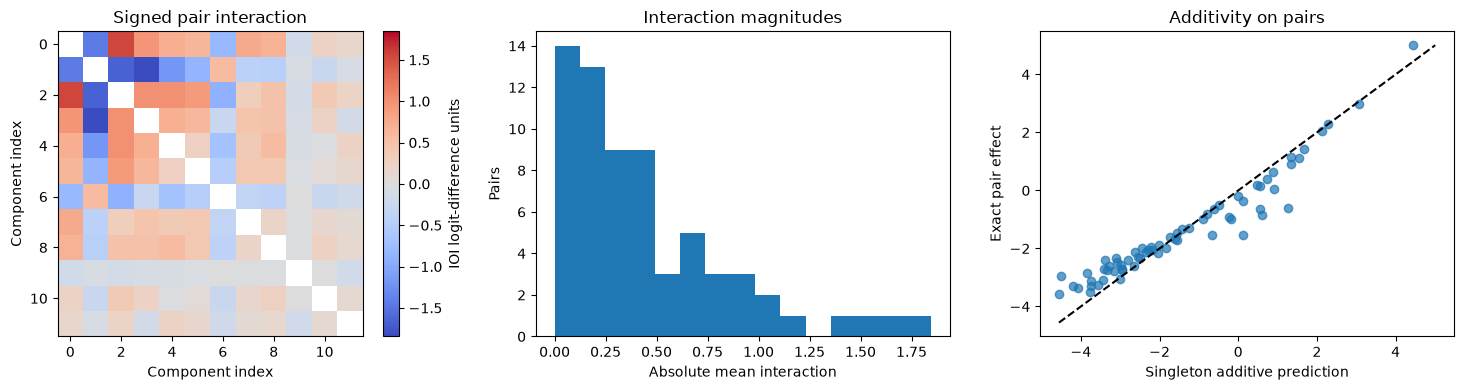

In [9]:
if pair_effects:
    interaction_arrays = {}
    with ledger.stage('interaction_statistics', f'{BOOTSTRAP_REPEATS} CPU prompt bootstraps per split; 0 forwards'):
        for split in pair_effects:
            table, summary, per_example, draws = an.pair_statistics(
                singletons[split], pair_effects[split], pairs, components, split, BOOTSTRAP_REPEATS, SEED)
            pair_tables[split] = table
            pair_summaries.append(summary)
            interaction_arrays[split] = per_example
            draws.to_csv(RUN_DIR / f'pair_bootstrap_{split}.csv', index=False)
    pd.concat(pair_tables.values(), ignore_index=True).to_csv(RUN_DIR / 'pairwise_interactions.csv', index=False)
    np.savez_compressed(RUN_DIR / 'pairwise_interactions_per_example.npz', pairs=np.array(pairs), **interaction_arrays)
    pd.DataFrame(pair_summaries).to_csv(RUN_DIR / 'pairwise_statistics.csv', index=False)
    display(pd.DataFrame(pair_summaries))
    display(pair_tables['validation'].nlargest(10, 'absolute_interaction'))
    an.pair_plots(pair_tables['validation'], N_COMPONENTS, RUN_DIR)
    plt.show()
else:
    print('No pair results; statistics and plots skipped.')

## 9. Multi-component masks with distinct mask splits

Sample uniformly without replacement at sizes 1, 2, approximately 25%, 50%, and
75% of heads. Finite singleton/pair pools limit the allocation; actual counts
are printed. No mask duplicates occur across train/validation/test mask splits.
The **official prompt splits remain separate**. Learned models see only training
masks on training prompts. Singletons are directly measured for the additive
baseline, and pair diagnostics include size-two test masks; those measurements
are not supplied to learned fits or used to choose hyperparameters. This makes
singleton additive performance on size-one training-prompt masks a construction
check, not an independent discovery result.

In [10]:
if RUN_RANDOM_MASKS:
    masks, allocation = an.mask_splits(N_COMPONENTS, SEED, TRAIN_MASKS_PER_DENSITY, EVAL_MASKS_PER_DENSITY)
    allocation.to_csv(RUN_DIR / 'mask_allocation.csv', index=False)
    display(allocation.pivot(index='mask_size', columns='mask_split', values='count'))
    print('Quadratic training rank:', np.linalg.matrix_rank(an.features(masks['train'], 2)),
          '/', an.features(masks['train'], 2).shape[1])
    total_masks = sum(map(len, masks.values()))
    estimate = total_masks*sum(math.ceil(len(d)/BATCH_SIZE) for d in datasets.values())
    with ledger.stage('random_masks', f'{total_masks} unique masks; <= {estimate} forward batches '
                      '(previous singleton/pair scores are cached)'), ledger.instrument(model):
        for prompt_split in datasets:
            mask_arrays[prompt_split] = {}
            for mask_split, z in masks.items():
                print(f'{prompt_split} prompts / {mask_split} masks: {len(z)} masks', flush=True)
                mask_arrays[prompt_split][mask_split] = scorer.effects(prompt_split, z)
    an.export_masks(RUN_DIR, masks, mask_arrays)
else:
    print('Random-mask acquisition skipped.')

mask_split,test,train,validation
mask_size,,,
1,4,4,4
2,16,34,16
3,16,64,16
6,16,64,16
9,16,64,16


Quadratic training rank: 78 / 78
random_masks: 366 unique masks; <= 1464 forward batches (previous singleton/pair scores are cached)


train prompts / train masks: 230 masks


train prompts / validation masks: 68 masks


train prompts / test masks: 68 masks


validation prompts / train masks: 230 masks


validation prompts / validation masks: 68 masks


validation prompts / test masks: 68 masks


random_masks: 0 actual forward batches, 3.69s wall


## 10. Two first-order predictors

The additive predictor uses exact training-prompt singleton effects. The learned
linear predictor fits random training masks on the same training prompts. Both
have zero intercept because the unmodified intervention effect is exactly zero.
Metrics are reported separately for held-out validation and test **masks**, and
for same-prompt-split versus cross-prompt-split evaluation. No test-mask target
is passed to fitting. NaN correlations/R² flag insufficient or constant strata.

In [11]:
predictions, coefficient_arrays, result_rows = {}, {}, []
if RUN_FITS:
    if not mask_arrays or not singletons:
        raise RuntimeError('Acquire random masks and singletons before fitting.')
    with ledger.stage('first_order_fits', 'CPU fits/evaluation on cached arrays; 0 forwards'):
        beta1 = an.fit(masks['train'], mask_arrays['train']['train'].mean(1), 1)
        for mask_split in ('validation', 'test'):
            z = masks[mask_split]
            predictions[mask_split] = {'additive singleton': z @ singletons['train'].mean(1),
                                       'learned first order': an.features(z, 1) @ beta1}
            for prompt_split in datasets:
                result_rows += an.prediction_rows(mask_arrays[prompt_split][mask_split].mean(1),
                                                  predictions[mask_split], z, prompt_split, mask_split)
    first_order_results = pd.DataFrame(result_rows)
    first_order_results.to_csv(RUN_DIR / 'first_order_results.csv', index=False)
    display(first_order_results.query("eval_prompt_split == 'validation' and mask_split == 'test'"))
else:
    print('First-order fitting skipped.')

first_order_fits: CPU fits/evaluation on cached arrays; 0 forwards


first_order_fits: 0 actual forward batches, 0.04s wall


,method,fit_prompt_split,eval_prompt_split,mask_split,mask_size,n_masks,MAE,Pearson,Spearman,R2
36,additive singleton,train,validation,test,all,68,1.269285,0.810515,0.823148,0.329772
37,additive singleton,train,validation,test,1,4,0.263351,0.999717,1.000000,0.977416
38,additive singleton,train,validation,test,2,16,0.633424,0.941498,0.844118,0.587276
39,additive singleton,train,validation,test,3,16,0.927161,0.921154,0.829412,0.347627
40,additive singleton,train,validation,test,6,16,2.022185,0.352530,0.217647,-9.123686
41,additive singleton,train,validation,test,9,16,1.745852,0.206556,0.305882,-8.447901
42,learned first order,train,validation,test,all,68,0.727224,0.916279,0.956560,0.828649
43,learned first order,train,validation,test,1,4,1.015223,0.899789,1.000000,0.465038
44,learned first order,train,validation,test,2,16,0.662787,0.861885,0.891176,0.638697
45,learned first order,train,validation,test,3,16,0.824423,0.842338,0.838235,0.615375


## 11. Explicit second-order regression

Fit the same targets with singleton features plus every `z_i*z_j` for `i < j`.
Use ordinary least squares with a verified full-column-rank training design;
no regularization tuning uses held-out masks. Compare all methods on identical
held-out masks. A paired prompt bootstrap measures second-order MAE improvement
over learned first order, conditional on the fitted models.

second_order_fit: CPU fit + paired prompt bootstrap; 0 forwards


second_order_fit: 0 actual forward batches, 0.03s wall


,method,fit_prompt_split,eval_prompt_split,mask_split,mask_size,n_masks,MAE,Pearson,Spearman,R2
36,additive singleton,train,validation,test,all,68,1.269285,0.810515,0.823148,0.329772
42,learned first order,train,validation,test,all,68,0.727224,0.916279,0.956560,0.828649
66,learned second order,train,validation,test,all,68,0.428057,0.972831,0.967783,0.942726


,MAE_improvement,ci_low,ci_high,scope
0,0.299167,0.109462,0.382027,Prompt bootstrap conditional on fixed training...


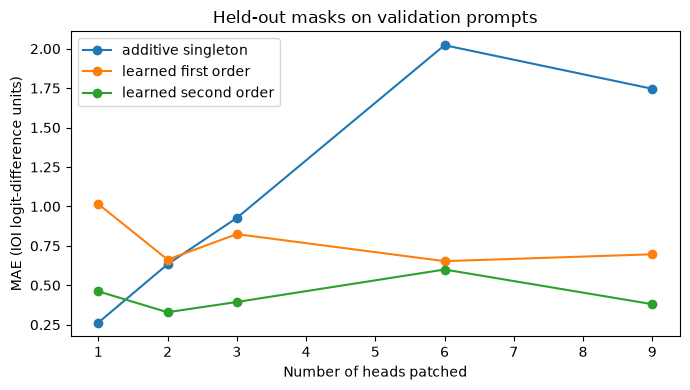

In [12]:
if RUN_FITS:
    with ledger.stage('second_order_fit', 'CPU fit + paired prompt bootstrap; 0 forwards'):
        beta2 = an.fit(masks['train'], mask_arrays['train']['train'].mean(1), 2)
        second_rows = []
        for mask_split in ('validation', 'test'):
            prediction = an.features(masks[mask_split], 2) @ beta2
            predictions[mask_split]['learned second order'] = prediction
            for prompt_split in datasets:
                second_rows += an.prediction_rows(mask_arrays[prompt_split][mask_split].mean(1),
                                                   {'learned second order': prediction}, masks[mask_split],
                                                   prompt_split, mask_split)
        second_order_results = pd.DataFrame(second_rows)
        all_results = pd.concat([first_order_results, second_order_results], ignore_index=True)
        comparison_ci = an.bootstrap_improvement(mask_arrays['validation']['test'],
                         predictions['test']['learned first order'], predictions['test']['learned second order'],
                         BOOTSTRAP_REPEATS, SEED)
    second_order_results.to_csv(RUN_DIR / 'second_order_results.csv', index=False)
    all_results.to_csv(RUN_DIR / 'prediction_summary.csv', index=False)
    np.savez_compressed(RUN_DIR / 'fitted_coefficients.npz', linear=beta1, quadratic=beta2, pairs=np.array(pairs))
    rt.write_json(RUN_DIR / 'second_order_improvement_bootstrap.json', comparison_ci)
    prediction_export = []
    for prompt_split in datasets:
        for mask_split in ('validation', 'test'):
            for index, mask in enumerate(masks[mask_split]):
                prediction_export.append({'prompt_split': prompt_split, 'mask_split': mask_split,
                                          'mask_index': index, 'mask_size': int(mask.sum()),
                                          'truth': mask_arrays[prompt_split][mask_split][index].mean(),
                                          **{name: p[index] for name, p in predictions[mask_split].items()}})
    pd.DataFrame(prediction_export).to_csv(RUN_DIR / 'heldout_predictions.csv', index=False)
    display(all_results.query("eval_prompt_split == 'validation' and mask_split == 'test' and mask_size == 'all'"))
    display(pd.DataFrame([comparison_ci]))
    an.error_plot(all_results, RUN_DIR)
    plt.show()

## 12. Generalization from training to validation IOI prompts

Keep coefficients and held-out masks fixed; change only the prompt set used for
the true effects. Positive `MAE_change` means worse cross-prompt prediction.
An optional exact-interaction expansion estimated on training prompts is reported
as an additional diagnostic, separately from the learned quadratic regression.

In [13]:
if all_results is not None:
    overall = all_results.query("mask_split == 'test' and mask_size == 'all'")
    same = overall.query("eval_prompt_split == 'train'").set_index('method')
    cross = overall.query("eval_prompt_split == 'validation'").set_index('method')
    generalization = pd.DataFrame({'same_split_MAE': same.MAE, 'cross_split_MAE': cross.MAE,
                                   'MAE_change': cross.MAE - same.MAE,
                                   'same_split_Spearman': same.Spearman, 'cross_split_Spearman': cross.Spearman})
    generalization.to_csv(RUN_DIR / 'prompt_generalization.csv')
    display(generalization)
    if pair_effects:
        interaction_train = pair_effects['train'].mean(1) - np.array([
            singletons['train'][i].mean() + singletons['train'][j].mean() for i, j in pairs])
        exact_prediction = (masks['test'] @ singletons['train'].mean(1) +
                            an.features(masks['test'], 2)[:, N_COMPONENTS:] @ interaction_train)
        diagnostic = pd.DataFrame([{'method': 'exact train singleton + pair expansion', 'eval_prompt_split': split,
                                     **an.metrics(mask_arrays[split]['test'].mean(1), exact_prediction)}
                                    for split in ('train', 'validation')])
        diagnostic.to_csv(RUN_DIR / 'exact_pair_expansion_generalization.csv', index=False)
        display(diagnostic)
else:
    print('No fitted predictions; generalization comparison skipped.')

,same_split_MAE,cross_split_MAE,MAE_change,same_split_Spearman,cross_split_Spearman
method,,,,,
additive singleton,1.171861,1.269285,0.097424,0.839371,0.823148
learned first order,0.642087,0.727224,0.085138,0.966943,0.956560
learned second order,0.324491,0.428057,0.103566,0.986945,0.967783


,method,eval_prompt_split,MAE,Pearson,Spearman,R2
0,exact train singleton + pair expansion,train,0.585624,0.880377,0.870290,0.738822
1,exact train singleton + pair expansion,validation,0.764586,0.870414,0.846776,0.699974


## 13. Sample efficiency on a fixed validation set

Re-fit using 16/32/64/128 training examples with repeated nested random subsets.
Targets are always the same validation prompts and validation masks. No new
forward passes are needed. Error bars show variability across training subsets,
not independent benchmark replicates. Singleton **magnitude** ranking stability
is measured against all selected training examples. Head selection remains fixed
from the separate EAP pass: this measures effect-estimation sample efficiency,
not end-to-end sample efficiency including selection.

sample_efficiency: 2 repeats at [4, 8, 16] example counts; 0 forwards


sample_efficiency: 0 actual forward batches, 0.08s wall


MAE  Spearman
n_train_examples method                                  
4                additive singleton    1.851339  0.806734
                 learned first order   1.014604  0.938982
                 learned second order  0.833561  0.959423
8                additive singleton    1.403073  0.828645
                 learned first order   0.885853  0.954117
                 learned second order  0.472266  0.974844
16               additive singleton    1.522416  0.803336
                 learned first order   0.888723  0.953506
                 learned second order  0.410225  0.970455

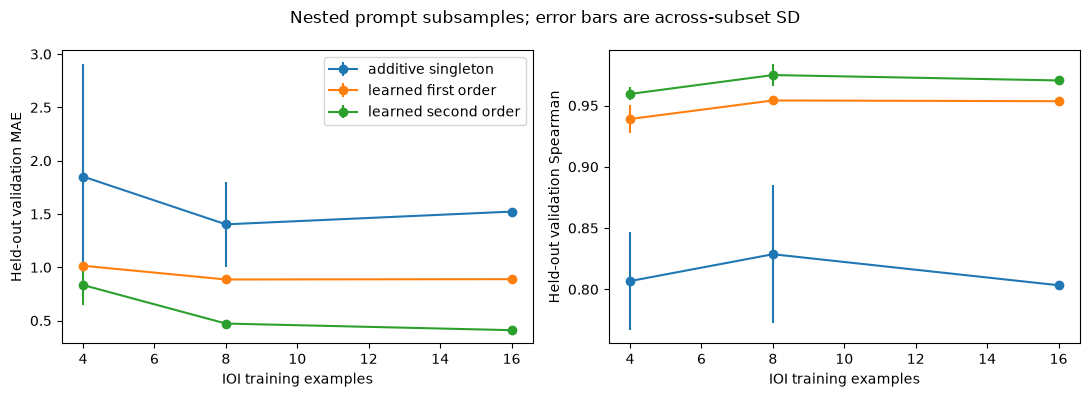

In [14]:
if RUN_SAMPLE_EFFICIENCY:
    if not mask_arrays or not singletons:
        raise RuntimeError('Acquire masks/singletons before the sample-efficiency cell.')
    with ledger.stage('sample_efficiency', f'{SAMPLE_REPEATS} repeats at {SAMPLE_SIZES} example counts; 0 forwards'):
        efficiency = an.sample_efficiency(masks, mask_arrays, singletons, SAMPLE_SIZES, SAMPLE_REPEATS, SEED)
    efficiency.to_csv(RUN_DIR / 'sample_efficiency.csv', index=False)
    display(efficiency.groupby(['n_train_examples', 'method'])[['MAE', 'Spearman']].mean())
    an.efficiency_plot(efficiency, RUN_DIR)
    plt.show()
else:
    print('Sample-efficiency experiment skipped.')

## 14. Compute accounting

One forward call is one batch, not one example and not one mask. Report example
forwards separately, including repeated donor/baseline passes. Every official
library forward is instrumented too. Cache hits never increment forward counts.
CUDA synchronizes around each measured forward and stage; stage wall time also
includes backwards, data transfer, and CPU overhead. Per-stage memory peaks
include the resident model. Acquisition costs shared by fits are not charged
again to each regression. The final export refreshes this table after MIB evaluation.

In [15]:
ledger.save()
display(pd.DataFrame(ledger.stages))
print('Actual forward batches:', len(ledger.calls))
print('Example-forwards:', sum(c['batch_size'] for c in ledger.calls))
print('Unique intervention masks:', len(ledger.mask_keys))

,stage,success,forward_passes_batches,successful_forward_passes,examples_processed,forward_seconds,wall_seconds,backward_calls,cache_hits,new_unique_masks,unique_masks_cumulative,component_count,peak_cuda_allocated_mib,peak_cuda_reserved_mib
0,model_loading,True,0,0,0,0.000000,1.928593,0,0,0,0,0,635.514160,690.0
1,data_loading,True,0,0,0,0.000000,5.070866,0,0,0,0,0,635.514160,690.0
2,raw_ioi_scores,True,8,8,64,0.969116,1.129269,0,0,1,1,1,1106.602051,1168.0
3,exact_intervention_checks,True,18,18,48,0.818238,1.411098,0,0,1,2,1,885.206055,1172.0
4,official_eap_selection,True,12,12,48,0.530832,1.406016,4,0,0,2,1,1681.740234,2160.0
5,singletons,True,0,0,0,0.000000,0.193102,0,28,0,2,12,651.764160,2160.0
6,exact_pairs,True,0,0,0,0.000000,0.807771,0,134,0,2,12,651.764160,2160.0
7,interaction_statistics,True,0,0,0,0.000000,0.270727,0,0,0,2,12,651.764160,2160.0
8,random_masks,True,0,0,0,0.000000,3.693576,0,738,0,2,12,651.764160,2160.0
9,first_order_fits,True,0,0,0,0.000000,0.040597,0,0,0,2,12,651.764160,2160.0


Actual forward batches: 38
Example-forwards: 160
Unique intervention masks: 2


## 15. Official baseline artifact and exact configuration

The training-only node EAP pass in section 5 is the official baseline; reuse its
graph rather than performing the attribution twice. It scores all graph source
nodes, whereas our interaction study uses the selected attention heads. The saved
configuration records the actual function, case-sensitive method, dataset indices,
batch size, code revisions, and graph path. It is a small-subset reproduction,
not a full leaderboard submission. Edge-level attribution remains future work.

In [16]:
if eap_graph is not None:
    display(pd.DataFrame([eap_config]))
    display(pd.DataFrame(ledger.stages).query("stage == 'official_eap_selection'"))
    print('Official graph:', eap_path)
else:
    print('EAP was skipped; component-only experiments remain valid, but no official baseline graph exists in this run.')

,api,method,intervention,level,aggregation,metric,mean,loss,model,task,split,n_examples,batch_size,seed,selected_filtered_indices,artifact,mib_commit,eap_commit
0,eap.attribute_node.attribute_node,EAP,patching,node,sum,logit_diff,True,True,gpt2,ioi,train,16,4,42,"[8132, 8268, 719, 8237, 4555, 6651, 5650, 9034...",H:\GenAI Research\sketch_prune\results\mib_ioi...,b759df34433c9e31043ba9e02908ce0bf20e894f,7af394a5662de8b23ad6154716a0cd3993d447a3


,stage,success,forward_passes_batches,successful_forward_passes,examples_processed,forward_seconds,wall_seconds,backward_calls,cache_hits,new_unique_masks,unique_masks_cumulative,component_count,peak_cuda_allocated_mib,peak_cuda_reserved_mib
4,official_eap_selection,True,12,12,48,0.530832,1.406016,4,0,0,2,1,1681.740234,2160.0


Official graph: H:\GenAI Research\sketch_prune\results\mib_ioi_20261014T222524Z_f369a20c\official_eap_node_importances.pt


## 16. Official MIB evaluation, with no homemade CPR/CMD

Call `MIB_circuit_track.evaluation.evaluate_area_under_curve` unchanged on the
saved EAP graph. It determines circuit sizes, pruning, normalization, and integration.
Save the exact returned fields (`weighted_edge_counts`, `area_under`,
`area_from_1`, `average`, `faithfulnesses`). These are **local subset** results,
not private-test leaderboard scores. Public-test evaluation requires the explicit
flag and uses fixed components/settings; never tune on it. The requested granularity
here is node-level, matching the official EAP graph.

In [17]:
mib_rows = []
if RUN_MIB_EVALUATION:
    if eap_graph is None:
        raise RuntimeError('Official evaluation requires RUN_EAP_SELECTION; it is independent of exact-pair acquisition.')
    for split in ['validation'] + (['test'] if RUN_PUBLIC_TEST else []):
        n_eval = min(N_MIB_EVAL_EXAMPLES, len(datasets[split]))
        eval_data = rt.subset(datasets[split], range(n_eval))
        with ledger.stage(f'official_mib_{split}', f'10 circuit sizes + clean/corrupted normalization; '
                          f'about {35*math.ceil(n_eval/MIB_EVAL_BATCH_SIZE)} forward batches'), ledger.instrument(model):
            # Re-load through the official serializer: graph node sets do not support deepcopy.
            official = rt.official_evaluation(model, Graph.from_pt(str(eap_path)), eval_data, MIB_EVAL_BATCH_SIZE)
        rt.write_json(RUN_DIR / f'mib_official_raw_{split}.json', official)
        mib_rows.append({'method': 'official EAP', 'model': 'gpt2', 'task': 'ioi', 'level': 'node',
                         'split': split, 'n_examples': n_eval, 'batch_size': MIB_EVAL_BATCH_SIZE,
                         'area_under': official['area_under'], 'area_from_1': official['area_from_1'],
                         'average': official['average'], 'scope': 'local official split subset'})
    pd.DataFrame(mib_rows).to_csv(RUN_DIR / 'mib_baseline_results.csv', index=False)
    display(pd.DataFrame(mib_rows))
else:
    print('Official MIB evaluation skipped by RUN_MIB_EVALUATION; no CPR/CMD values are generated.')

official_mib_validation: 10 circuit sizes + clean/corrupted normalization; about 70 forward batches


  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:00<00:00,  3.84it/s]

100%|██████████| 2/2 [00:00<00:00,  5.61it/s]

Computing results for 0.1% of nodes (N=0)
Computing results for 0.2% of nodes (N=0)


Computing results for 0.5% of nodes (N=0)
Computing results for 1.0% of nodes (N=1)


... (2 outputs left out)

Computing results for 10.0% of nodes (N=15)
Computing results for 20.0% of nodes (N=31)


Computing results for 50.0% of nodes (N=78)
Computing results for 100% of nodes (N=157)


official_mib_validation: 48 actual forward batches, 3.33s wall


,method,model,task,level,split,n_examples,batch_size,area_under,area_from_1,average,scope
0,official EAP,gpt2,ioi,node,validation,8,4,0.607769,0.391231,0.189442,local official split subset


## 17. Research decision checkpoint — generated from results only

The interaction effect-size threshold and ranking threshold were fixed in the
configuration cell. This is an exploratory checkpoint for selected heads and
sampled prompts. Missing stages produce “not measured,” never inferred outcomes.

In [18]:
answers = []
validation_pair_summary = next((r for r in pair_summaries if r['prompt_split'] == 'validation'), None)
if validation_pair_summary:
    r = validation_pair_summary
    verdict = ('above' if r['relative_mean_interaction_ci_low'] > MEANINGFUL_INTERACTION_RATIO else
               'below' if r['relative_mean_interaction_ci_high'] < MEANINGFUL_INTERACTION_RATIO else 'uncertain against')
    answers.append(f"A. Validation mean |interaction| = {r['mean_absolute_interaction']:.4f}; "
                   f"relative scale = {r['relative_mean_interaction']:.1%} "
                   f"(95% CI {r['relative_mean_interaction_ci_low']:.1%}--{r['relative_mean_interaction_ci_high']:.1%}), "
                   f"{verdict} the prespecified {MEANINGFUL_INTERACTION_RATIO:.0%} criterion. "
                   f"{r['BY_significant_pairs_0.05']}/{r['n_pairs']} signed-pair tests pass BY FDR 0.05.")
else:
    answers.append('A. Pair interactions: not measured.')
if comparison_ci is not None:
    r = comparison_ci
    verdict = 'supported' if r['ci_low'] > 0 else 'not established'
    answers.append(f"B. Second-order MAE improvement over learned first order = {r['MAE_improvement']:.4f} "
                   f"(95% prompt CI {r['ci_low']:.4f}--{r['ci_high']:.4f}); improvement {verdict}.")
    size_rows = all_results.query("eval_prompt_split == 'validation' and mask_split == 'test' and mask_size != 'all'")
    size_table = size_rows.pivot(index='mask_size', columns='method', values='MAE').sort_index()
    gain = size_table['learned first order'] - size_table['learned second order']
    answers.append('C. MAE improvement by mask size: ' + ', '.join(f'{int(k)} heads: {v:.4f}' for k, v in gain.items()) +
                   '. This descriptive pattern does not establish a monotonic trend.')
    drop = generalization.loc['learned second order']
    answers.append(f"D. Quadratic same-prompt-split MAE {drop.same_split_MAE:.4f}; validation-prompt MAE "
                   f"{drop.cross_split_MAE:.4f}; change {drop.MAE_change:+.4f}. Coefficients were fitted on train prompts only.")
else:
    answers += ['B. Held-out model comparison: not measured.', 'C. Density trend: not measured.',
                'D. Cross-prompt prediction: not measured.']
if efficiency is not None and not efficiency.empty:
    rank_table = efficiency.query("method == 'additive singleton'").groupby('n_train_examples')[
        'singleton_magnitude_rank_vs_full_train'].agg(['mean', 'min'])
    # Exclude the full-data self-comparison, which necessarily has rank correlation 1.
    eligible = rank_table[(rank_table.index < N_TRAIN) & (rank_table['min'] >= RANK_STABILITY_THRESHOLD)]
    finding = (f'{int(eligible.index.min())} examples is the first tested count meeting the '
               f'{RANK_STABILITY_THRESHOLD:.2f} rank threshold in every repeat' if len(eligible) else
               'No tested proper subset meets the ranking threshold in every repeat')
    answers.append('E. ' + finding + '; conditional on fixed EAP-selected heads and a full-train reference.')
else:
    answers.append('E. Sample efficiency/ranking stability: not measured.')
pair_stages = [s for s in ledger.stages if s['stage'] == 'exact_pairs']
if pair_stages:
    s = pair_stages[-1]
    answers.append(f"F. Exact pairs: {len(pairs)} unique pairs across {len(pair_effects)} prompt splits, "
                   f"{s['forward_passes_batches']} actual forward batches, {s['examples_processed']} example-forwards, "
                   f"{s['wall_seconds']:.2f}s wall; peak allocated CUDA {s['peak_cuda_allocated_mib']:.1f} MiB. "
                   'Baseline/donor acquisition is separately charged in compute_accounting.csv.')
else:
    answers.append('F. Exact pair cost: not measured.')
checkpoint = '\n\n'.join(answers)
(RUN_DIR / 'research_checkpoint.md').write_text(checkpoint, encoding='utf-8')
display(Markdown(checkpoint))

A. Validation mean |interaction| = 0.4523; relative scale = 14.8% (95% CI 13.0%--17.4%), above the prespecified 5% criterion. 46/66 signed-pair tests pass BY FDR 0.05.

B. Second-order MAE improvement over learned first order = 0.2992 (95% prompt CI 0.1095--0.3820); improvement supported.

C. MAE improvement by mask size: 1 heads: 0.5537, 2 heads: 0.3335, 3 heads: 0.4302, 6 heads: 0.0530, 9 heads: 0.3163. This descriptive pattern does not establish a monotonic trend.

D. Quadratic same-prompt-split MAE 0.3245; validation-prompt MAE 0.4281; change +0.1036. Coefficients were fitted on train prompts only.

E. 4 examples is the first tested count meeting the 0.90 rank threshold in every repeat; conditional on fixed EAP-selected heads and a full-train reference.

F. Exact pairs: 66 unique pairs across 2 prompt splits, 0 actual forward batches, 0 example-forwards, 0.81s wall; peak allocated CUDA 651.8 MiB. Baseline/donor acquisition is separately charged in compute_accounting.csv.

## 18. Export configuration, provenance, and all completed stages

CSV files contain aggregate results; NPZ files preserve mask-by-example arrays.
Their example columns align with `ioi_examples.csv` within each prompt split;
pair rows align with the saved `pairs` array, and component indices with
`selected_components.csv`. Score caches use a provenance-dependent directory.
Skipped stages do not produce fabricated CSV rows.

In [19]:
package_names = ['torch', 'transformer-lens', 'transformers', 'datasets', 'numpy', 'pandas', 'scipy', 'matplotlib']
config = {'model_key': 'gpt2', 'model': MODEL_NAME_TO_FULLNAME['gpt2'], 'task': 'ioi',
          'dataset': 'mib-bench/' + TASKS_TO_HF_NAMES['ioi'], 'dataset_splits': sizes,
          'seed': SEED, 'components': components, 'component_count': N_COMPONENTS,
          'intervention_type': 'matched s2_io_flip_counterfactual head-result replacement at all positions',
          'batch_size': BATCH_SIZE, 'eap_batch_size': EAP_BATCH_SIZE, 'eap_examples': N_EAP_EXAMPLES,
          'mask_train_per_density': TRAIN_MASKS_PER_DENSITY, 'mask_eval_per_density': EVAL_MASKS_PER_DENSITY,
          'sample_sizes': SAMPLE_SIZES, 'sample_repeats': SAMPLE_REPEATS,
          'bootstrap_repeats': BOOTSTRAP_REPEATS, 'meaningful_interaction_ratio': MEANINGFUL_INTERACTION_RATIO,
          'rank_stability_threshold': RANK_STABILITY_THRESHOLD, 'device': DEVICE,
          'gpu': torch.cuda.get_device_name(0), 'dtype': str(model.cfg.dtype),
          'packages': {p: importlib.metadata.version(p) for p in package_names},
          'provenance': provenance, 'cache_signature': signature, 'dataset_info': dataset_info,
          'run_flags': {k: v for k, v in globals().copy().items() if k.startswith('RUN_') and isinstance(v, bool)},
          'score_semantics': 'raw IOI correct-minus-incorrect logit difference; effects are patched minus clean',
          'mib_evaluation_scope': 'official evaluator on local split subset, not private leaderboard scores'}
rt.write_json(RUN_DIR / 'experiment_config.json', config)
ledger.save()
display(pd.DataFrame(ledger.stages))
print('Saved:', RUN_DIR)
print('Forward batches:', len(ledger.calls), '| example-forwards:', sum(c['batch_size'] for c in ledger.calls),
      '| cache hits:', ledger.hits, '| unique masks:', len(ledger.mask_keys))
display(pd.DataFrame({'artifact': [p.name for p in sorted(RUN_DIR.iterdir()) if p.is_file()]}))

,stage,success,forward_passes_batches,successful_forward_passes,examples_processed,forward_seconds,wall_seconds,backward_calls,cache_hits,new_unique_masks,unique_masks_cumulative,component_count,peak_cuda_allocated_mib,peak_cuda_reserved_mib
0,model_loading,True,0,0,0,0.000000,1.928593,0,0,0,0,0,635.514160,690.0
1,data_loading,True,0,0,0,0.000000,5.070866,0,0,0,0,0,635.514160,690.0
2,raw_ioi_scores,True,8,8,64,0.969116,1.129269,0,0,1,1,1,1106.602051,1168.0
3,exact_intervention_checks,True,18,18,48,0.818238,1.411098,0,0,1,2,1,885.206055,1172.0
4,official_eap_selection,True,12,12,48,0.530832,1.406016,4,0,0,2,1,1681.740234,2160.0
5,singletons,True,0,0,0,0.000000,0.193102,0,28,0,2,12,651.764160,2160.0
6,exact_pairs,True,0,0,0,0.000000,0.807771,0,134,0,2,12,651.764160,2160.0
7,interaction_statistics,True,0,0,0,0.000000,0.270727,0,0,0,2,12,651.764160,2160.0
8,random_masks,True,0,0,0,0.000000,3.693576,0,738,0,2,12,651.764160,2160.0
9,first_order_fits,True,0,0,0,0.000000,0.040597,0,0,0,2,12,651.764160,2160.0


Saved: H:\GenAI Research\sketch_prune\results\mib_ioi_20261014T222524Z_f369a20c
Forward batches: 86 | example-forwards: 352 | cache hits: 900 | unique masks: 2


,artifact
0,compute_accounting.csv
1,dataset_manifest.json
2,exact_pair_expansion_generalization.csv
3,experiment_config.json
4,first_order_results.csv
5,fitted_coefficients.npz
6,forward_log.csv
7,heldout_predictions.csv
8,intervention_checks.json
9,ioi_examples.csv


## 19. Interpretation boundaries and incremental execution

- `RUN_SINGLETONS` and `RUN_PAIRS` do not require random-mask fitting or official
  circuit evaluation. Set those later flags false for a focused exact experiment.
- For incremental kernel sessions, rerun a stage using its existing scorer to use
  caches. `RESUME_DIR` can reuse exact scores only when the cache signature matches;
  newly measured costs then describe the resumed run, not the original acquisition.
- OOM raises an explicit error; lower the relevant batch size and restart/reconfigure
  deliberately. Batch size enters the cache identity. No automatic sample reduction.
- These experiments establish prediction behavior over a selected head set.
  Head selection, bootstrap conditioning, finite density coverage, and subset-size
  uncertainty limit generalization. Public test must remain outside model selection.
- The official baseline evaluates all graph nodes; our 12--16-head surrogate is
  not yet a submitted MIB circuit-discovery method. Edge-level integration and
  efficient higher-order sketching are follow-on experiments.